In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import re
from bs4 import BeautifulSoup

import warnings
warnings.filterwarnings('ignore')

In [6]:
df = pd.read_csv('../train.csv')

In [7]:
new_df = df.sample(30000,random_state=2)

In [8]:
def preprocess(q):
    q = str(q).lower().strip()
    
    # Replace certain special characters with their string equivalents:
    q = q.replace('%', ' percent')
    q = q.replace('$', ' dollar ')
    q = q.replace('₹', ' rupee ')
    q = q.replace('€', ' euro ')
    q = q.replace('@', ' at ')


    # The pattern '[math]' appears around 900 times in the whole dataset.
    q = q.replace('[math]', '')

    # Replacing some numbers with string equivalents (not perfect, can be done better to account for more cases)
    q = q.replace(',000,000,000 ', 'b ')
    q = q.replace(',000,000 ', 'm ')
    q = q.replace(',000 ', 'k ')
    q = re.sub(r'([0-9]+)000000000', r'\1b', q)
    q = re.sub(r'([0-9]+)000000', r'\1m', q)
    q = re.sub(r'([0-9]+)000', r'\1k', q)

    # Decontracting words
    # https://en.wikipedia.org/wiki/Wikipedia%3aList_of_English_contractions
    # https://stackoverflow.com/a/19794953
    contractions = { 
    "ain't": "am not",
    "aren't": "are not",
    "can't": "can not",
    "can't've": "can not have",
    "'cause": "because",
    "could've": "could have",
    "couldn't": "could not",
    "couldn't've": "could not have",
    "didn't": "did not",
    "doesn't": "does not",
    "don't": "do not",
    "hadn't": "had not",
    "hadn't've": "had not have",
    "hasn't": "has not",
    "haven't": "have not",
    "he'd": "he would",
    "he'd've": "he would have",
    "he'll": "he will",
    "he'll've": "he will have",
    "he's": "he is",
    "how'd": "how did",
    "how'd'y": "how do you",
    "how'll": "how will",
    "how's": "how is",
    "i'd": "i would",
    "i'd've": "i would have",
    "i'll": "i will",
    "i'll've": "i will have",
    "i'm": "i am",
    "i've": "i have",
    "isn't": "is not",
    "it'd": "it would",
    "it'd've": "it would have",
    "it'll": "it will",
    "it'll've": "it will have",
    "it's": "it is",
    "let's": "let us",
    "ma'am": "madam",
    "mayn't": "may not",
    "might've": "might have",
    "mightn't": "might not",
    "mightn't've": "might not have",
    "must've": "must have",
    "mustn't": "must not",
    "mustn't've": "must not have",
    "needn't": "need not",
    "needn't've": "need not have",
    "o'clock": "of the clock",
    "oughtn't": "ought not",
    "oughtn't've": "ought not have",
    "shan't": "shall not",
    "sha'n't": "shall not",
    "shan't've": "shall not have",
    "she'd": "she would",
    "she'd've": "she would have",
    "she'll": "she will",
    "she'll've": "she will have",
    "she's": "she is",
    "should've": "should have",
    "shouldn't": "should not",
    "shouldn't've": "should not have",
    "so've": "so have",
    "so's": "so as",
    "that'd": "that would",
    "that'd've": "that would have",
    "that's": "that is",
    "there'd": "there would",
    "there'd've": "there would have",
    "there's": "there is",
    "they'd": "they would",
    "they'd've": "they would have",
    "they'll": "they will",
    "they'll've": "they will have",
    "they're": "they are",
    "they've": "they have",
    "to've": "to have",
    "wasn't": "was not",
    "we'd": "we would",
    "we'd've": "we would have",
    "we'll": "we will",
    "we'll've": "we will have",
    "we're": "we are",
    "we've": "we have",
    "weren't": "were not",
    "what'll": "what will",
    "what'll've": "what will have",
    "what're": "what are",
    "what's": "what is",
    "what've": "what have",
    "when's": "when is",
    "when've": "when have",
    "where'd": "where did",
    "where's": "where is",
    "where've": "where have",
    "who'll": "who will",
    "who'll've": "who will have",
    "who's": "who is",
    "who've": "who have",
    "why's": "why is",
    "why've": "why have",
    "will've": "will have",
    "won't": "will not",
    "won't've": "will not have",
    "would've": "would have",
    "wouldn't": "would not",
    "wouldn't've": "would not have",
    "y'all": "you all",
    "y'all'd": "you all would",
    "y'all'd've": "you all would have",
    "y'all're": "you all are",
    "y'all've": "you all have",
    "you'd": "you would",
    "you'd've": "you would have",
    "you'll": "you will",
    "you'll've": "you will have",
    "you're": "you are",
    "you've": "you have"
    }


    q_decontracted = []

    for word in q.split():
        if word in contractions:
            word = contractions[word]

        q_decontracted.append(word)

    q = ' '.join(q_decontracted)
    q = q.replace("'ve", " have")
    q = q.replace("n't", " not")
    q = q.replace("'re", " are")
    q = q.replace("'ll", " will")
    
    # Removing HTML tags
    q = BeautifulSoup(q)
    q = q.get_text()
    
    # Remove punctuations
    pattern = re.compile('\W')
    q = re.sub(pattern, ' ', q).strip()

   # remove all kinds of whitespace
    q = re.sub(r'\s+', ' ', q).strip()
    
    return q

In [9]:
# apply the preprocess function on dataset 

new_df['question1'] = new_df['question1'].apply(preprocess)
new_df['question2'] = new_df['question2'].apply(preprocess)

In [10]:
# Create a new columns 'q1_len', q2_len char lenth of q1 and q2

new_df['q1_len'] = new_df['question1'].str.len() 
new_df['q2_len'] = new_df['question2'].str.len()

In [11]:
# create a new column of 'q1_num_words'  words in q1

new_df['q1_num_words'] = new_df['question1'].apply(lambda row: len(row.split(" ")))
new_df['q2_num_words'] = new_df['question2'].apply(lambda row: len(row.split(" ")))
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9


In [12]:
def common_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return len(w1 & w2)

In [13]:
new_df['word_common'] = new_df.apply(common_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,12
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,7
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20,3
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30,0
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9,3


In [14]:
def total_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))    
    return (len(w1) + len(w2))

In [15]:
new_df['word_total'] = new_df.apply(total_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,12,26
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,7,22
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20,3,36
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30,0,32
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9,3,13


In [16]:
new_df['word_share'] = round(new_df['word_common']/new_df['word_total'],2)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,12,26,0.46
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,7,22,0.32
327711,327711,454161,454162,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...,0,102,118,26,20,3,36,0.08
367788,367788,498109,491396,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...,0,57,143,13,30,0,32,0.00
151235,151235,237843,50930,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy,0,34,49,5,9,3,13,0.23


# Advanced Features

In [17]:
import nltk

# nltk.download('stopwords')

In [18]:
import nltk
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))
print(stop_words)

{'from', 'down', 'such', "didn't", 'should', 't', 'the', 'and', 're', 'herself', 'when', "they'd", 'him', 'or', 's', 'himself', "isn't", "mightn't", 'those', 'an', 'if', 'me', "they're", "he's", 'as', 'some', "she'd", 'had', 'through', 'who', 'have', 'so', 'in', 'you', 'will', "i'll", "we're", 'this', "don't", 'your', 'aren', "shan't", 'were', 'hers', 've', "needn't", "shouldn't", "wouldn't", 'into', 'over', 'their', "hasn't", 'needn', 'is', 'until', 'before', 'no', 'hadn', "you've", 'wouldn', "that'll", 'o', 'wasn', 'of', 'because', "mustn't", 'i', 'but', 'here', "i'd", 'not', "we'd", "you'd", 'each', 'myself', 'ma', "wasn't", 'once', 'am', 'll', "hadn't", 'own', 'be', 'most', 'isn', 'd', 'more', 'other', 'mustn', "she'll", "we've", 'doing', "couldn't", 'again', "doesn't", 'her', 'our', 'further', "we'll", "aren't", 'having', 'his', 'just', 'them', "weren't", 'under', "you'll", 'my', 'about', 'few', 'by', 'being', 'then', 'to', "you're", 'after', "he'll", 'been', 'against', "it'll", '

In [19]:
# Advanced Features
from nltk.corpus import stopwords

def fetch_token_features(row):
    
    q1 = row['question1']
    q2 = row['question2']
    
    SAFE_DIV = 0.0001 

    STOP_WORDS = stopwords.words("english")
    
    token_features = [0.0]*8
    
    # Converting the Sentence into Tokens: 
    q1_tokens = q1.split()
    q2_tokens = q2.split()
    
    if len(q1_tokens) == 0 or len(q2_tokens) == 0:
        return token_features

    # Get the non-stopwords in Questions
    q1_words = set([word for word in q1_tokens if word not in STOP_WORDS])
    q2_words = set([word for word in q2_tokens if word not in STOP_WORDS])

    # get the stopwords in questions:
    q1_stops = set([word for word in q1_tokens if word in STOP_WORDS])
    q2_stops = set([word for word in q2_tokens if word in STOP_WORDS])

    # Get the common non-stopwords from question pair
    common_word_count = len(q1_words.intersection(q2_words))

    # Get the common stopwords from question pair
    common_stop_count = len(q1_stops.intersection(q2_stops))

    # Get the common tokens from question pair
    common_token_count = len(set(q1_tokens).intersection(set(q2_tokens)))


    token_features[0] = common_word_count / (min(len(q1_words), len(q2_words)) + SAFE_DIV)
    token_features[1] = common_word_count / (max(len(q1_words), len(q2_words)) + SAFE_DIV)
    token_features[2] = common_stop_count / (min(len(q1_stops), len(q2_stops)) + SAFE_DIV)
    token_features[3] = common_stop_count / (max(len(q1_stops), len(q2_stops)) + SAFE_DIV)
    token_features[4] = common_token_count / (min(len(q1_tokens), len(q2_tokens)) + SAFE_DIV)
    token_features[5] = common_token_count / (max(len(q1_tokens), len(q2_tokens)) + SAFE_DIV)

    # Last word of both question is same or not
    token_features[6] = int(q1_tokens[-1] == q2_tokens[-1])

    # First word of both question is same or not
    token_features[7] = int(q1_tokens[0] == q2_tokens[0])

    return token_features
    

In [20]:
token_features = new_df.apply(fetch_token_features, axis = 1)

In [21]:
new_df['cwc_min'] = list(map(lambda x: x[0], token_features))
new_df['cwc_max'] = list(map(lambda x: x[1], token_features))
new_df['csc_min'] = list(map(lambda x: x[2], token_features))
new_df['csc_max'] = list(map(lambda x: x[3], token_features))
new_df['ctc_min'] = list(map(lambda x: x[4], token_features))
new_df['ctc_max'] = list(map(lambda x: x[5], token_features))
new_df['last_word_eq'] = list(map(lambda x: x[6], token_features))
new_df['first_word_eq'] = list(map(lambda x: x[7], token_features))

# Length Based Features

In [22]:
# Length Based Features
import distance

def fetch_length_features(row):
    q1 = row['question1']
    q2 = row['question2']

    length_features = [0.0]*3

    # Converting the sentance into tokens:
    q1_tokens = q1.split()
    q2_tokens = q2.split()

    if len(q1_tokens) == 0 or len(q2_tokens) == 0:
        return length_features

    # Absolute length features
    length_features[0] = abs(len(q1_tokens) - len(q2_tokens))

    # Average Token Length of both Questions   
    length_features[1] = (len(q1_tokens) + len(q2_tokens))/2

    strs = list(distance.lcsubstrings(q1, q2))
    length_features[2] = len(strs[0]) / (min(len(q1), len(q2)) + 1)

    return length_features


In [23]:
length_features = new_df.apply(fetch_length_features, axis=1)

new_df['abs_len_diff'] = list(map(lambda x: x[0], length_features))
new_df['mean_len'] = list(map(lambda x: x[1], length_features))
new_df['longest_substr_ratio'] = list(map(lambda x: x[2], length_features))

# Fuzzy Features

In [24]:
# Fuzzy Features

from fuzzywuzzy import fuzz

def fetch_fuzzy_features(row):
    q1 = row['question1']
    q2 = row['question2']

    fuzzy_features = [0.0]*4

    # fuzz_ratio
    fuzzy_features[0] = fuzz.QRatio(q1, q2)  # Usage: This provides a similarity score by performing an exact character-by-character comparison of the two strings (case-sensitive).

    # fuzz_partial_ratio
    fuzzy_features[1] = fuzz.partial_ratio(q1, q2)   # Use: Yeh substring matching ke liye hota hai. Agar ek string choti hai aur wo badi string ke andar kahi bhi milti hai, toh yeh high score deta hai.


 # Use: Yeh words ko alphabetical order mein sort karke compare karta hai. Isse farq nahi padta ki words aage-piche likhe hain ya nahi (jaise "machine learning" aur "learning machine").
    # token_sort_ratio
    fuzzy_features[2] = fuzz.token_sort_ratio(q1, q2)   


# Usage: It ignores duplicate words and matches overlapping words without regard to order.
    # token_set_ratio
    fuzzy_features[3] = fuzz.token_set_ratio(q1, q2)  


    return fuzzy_features


In [25]:
fuzzy_features = new_df.apply(fetch_fuzzy_features, axis=1)

# Creating new feature columns for fuzzy features
new_df['fuzz_ratio'] = list(map(lambda x: x[0], fuzzy_features))
new_df['fuzz_partial_ratio'] = list(map(lambda x: x[1], fuzzy_features))
new_df['token_sort_ratio'] = list(map(lambda x: x[2], fuzzy_features))
new_df['token_set_ratio'] = list(map(lambda x: x[3], fuzzy_features))

In [26]:
new_df.shape

(30000, 28)

In [27]:
new_df.columns

Index(['id', 'qid1', 'qid2', 'question1', 'question2', 'is_duplicate',
       'q1_len', 'q2_len', 'q1_num_words', 'q2_num_words', 'word_common',
       'word_total', 'word_share', 'cwc_min', 'cwc_max', 'csc_min', 'csc_max',
       'ctc_min', 'ctc_max', 'last_word_eq', 'first_word_eq', 'abs_len_diff',
       'mean_len', 'longest_substr_ratio', 'fuzz_ratio', 'fuzz_partial_ratio',
       'token_sort_ratio', 'token_set_ratio'],
      dtype='str')

# Perform EDA on new columns 

In [28]:
ques_df = new_df[['question1','question2']]
ques_df.head()

,question1,question2
398782,what is the best marketing automation tool for...,what is the best marketing automation tool for...
115086,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...
327711,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...
367788,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...
151235,consequences of bhopal gas tragedy,what was the reason behind the bhopal gas tragedy


In [29]:
final_df = new_df.drop(columns=['id','qid1','qid2','question1','question2'])
print(final_df.shape)
final_df.head()

(30000, 23)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio,fuzz_ratio,fuzz_partial_ratio,token_sort_ratio,token_set_ratio
398782,1,75,76,13,13,12,26,0.46,0.874989,0.874989,...,0.923070,1.0,1.0,0.0,13.0,0.855263,99,99,99,99
115086,0,47,55,12,15,7,22,0.32,0.666644,0.499988,...,0.466664,1.0,1.0,3.0,13.5,0.229167,69,66,65,74
327711,0,102,118,26,20,3,36,0.08,0.000000,0.000000,...,0.115384,0.0,0.0,6.0,23.0,0.048544,26,30,34,43
367788,0,57,143,13,30,0,32,0.00,0.000000,0.000000,...,0.000000,0.0,0.0,17.0,21.5,0.051724,27,46,23,30
151235,0,34,49,5,9,3,13,0.23,0.749981,0.599988,...,0.333330,1.0,0.0,4.0,7.0,0.542857,55,70,48,69


In [30]:
final_df.columns

Index(['is_duplicate', 'q1_len', 'q2_len', 'q1_num_words', 'q2_num_words',
       'word_common', 'word_total', 'word_share', 'cwc_min', 'cwc_max',
       'csc_min', 'csc_max', 'ctc_min', 'ctc_max', 'last_word_eq',
       'first_word_eq', 'abs_len_diff', 'mean_len', 'longest_substr_ratio',
       'fuzz_ratio', 'fuzz_partial_ratio', 'token_sort_ratio',
       'token_set_ratio'],
      dtype='str')

In [31]:
from sklearn.feature_extraction.text import CountVectorizer
# merge texts
questions = list(ques_df['question1']) + list(ques_df['question2'])

cv = CountVectorizer(max_features=3000)
q1_arr, q2_arr = np.vsplit(cv.fit_transform(questions).toarray(),2)


In [32]:
temp_df1 = pd.DataFrame(q1_arr, index= ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index= ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis=1)
temp_df.shape

(30000, 6000)

In [33]:
final_df = pd.concat([final_df, temp_df], axis=1)
print(final_df.shape)
final_df.head()

(30000, 6023)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,2990,2991,2992,2993,2994,2995,2996,2997,2998,2999
398782,1,75,76,13,13,12,26,0.46,0.874989,0.874989,...,0,0,0,0,0,0,0,0,0,0
115086,0,47,55,12,15,7,22,0.32,0.666644,0.499988,...,0,0,0,0,0,0,0,0,0,0
327711,0,102,118,26,20,3,36,0.08,0.000000,0.000000,...,0,0,0,0,0,0,0,0,0,0
367788,0,57,143,13,30,0,32,0.00,0.000000,0.000000,...,0,0,0,1,0,0,0,0,0,0
151235,0,34,49,5,9,3,13,0.23,0.749981,0.599988,...,0,0,0,0,0,0,0,0,0,0


# with CountVector

In [34]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(final_df.iloc[:,1:].values,final_df.iloc[:,0].values,test_size=0.2,random_state=1)

In [35]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

In [36]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
accuracy_score(y_test, y_pred)


0.7036666666666667

Using CountVectorizer without StandardScaler, the model achieved 0.7036666% accuracy.
Using ConutVectore and StandardScaler the model achieved 0.6795% accuracy.

## check the k value 

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

accuray = []
for i in range(1, 10):
    knn = KNeighborsClassifier(n_neighbors = i)
    knn.fit(X_train_sc, y_train)
    y_pred = knn.predict(X_test_sc)
    accuray.append(accuracy_score(y_test, y_pred))

plt.plot(range(1, 10), accuray)


### use the parameters 

In [ ]:
# use the parameters 

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors = 7, weights = 'distance', metric='cosine')
knn.fit(X_train_sc, y_train)
y_pred = knn.predict(X_test_sc)
accuracy_score(y_test, y_pred)


### Accuracy with metric parameter 
euclidean (metric='minkowski', p=2) = 0.7673333333333333.

cosine (metric='cosine') = 0.7525. 


In [ ]:
X_test_sc.shape

# Support Vector Machine

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
svc = SVC()

svc.fit(X_train_sc, y_train)

y_pred = svc.predict(X_test_sc)


In [ ]:
# 1. Required Libraries Import karein
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

svm_model = SVC(
    C=1.0,               # Regularization parameter
    kernel='rbf',        # Non-linear kernel
    gamma='scale',       # Influence range of data points
    probability=True,    # True karne par humein .predict_proba() milta hai aur probA_ generate hota hai
    verbose=True,        # Training ke logs screen par print honge
    random_state=42
)

svm_model.fit(X_train, y_train)

# 6. Test data par predictions nikalein
y_pred = svm_model.predict(X_test)

# 7. Probabilities bhi check kar sakte hain (Kyunki probability=True kiya tha)
y_prob = svm_model.predict_proba(X_test)

# 8. Model ki performance evaluate karein
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

# 9. Training ke baad generate hone wali probA_ attribute dekh sakte hain
print("Fitted Platt Scaling Parameter (probA_):")
print(svm_model.probA_)

In [38]:
from mlxtend.plotting import plot_decision_regions

# word2Vex 

In [92]:
new_df_1 = new_df
new_df_1.head(2)

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,...,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio,fuzz_ratio,fuzz_partial_ratio,token_sort_ratio,token_set_ratio
398782,398782,496695,532029,what is the best marketing automation tool for...,what is the best marketing automation tool for...,1,75,76,13,13,...,0.923070,1.0,1.0,0.0,13.0,0.855263,99,99,99,99
115086,115086,187729,187730,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...,0,47,55,12,15,...,0.466664,1.0,1.0,3.0,13.5,0.229167,69,66,65,74


In [93]:
ques_df = new_df_1[['question1','question2']]
ques_df.head(4)

,question1,question2
398782,what is the best marketing automation tool for...,what is the best marketing automation tool for...
115086,i am poor but i want to invest what should i do,i am quite poor and i want to be very rich wha...
327711,i am from india and live abroad i met a guy fr...,t i e t to thapar university to thapar univers...
367788,why do so many people in the u s hate the sout...,my boyfriend doesnt feel guilty when he hurts ...


In [94]:
final_df_1 = new_df_1.drop(columns=['id','qid1','qid2','question1','question2'])
print(final_df_1.shape)
final_df_1.head()

(30000, 23)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,ctc_max,last_word_eq,first_word_eq,abs_len_diff,mean_len,longest_substr_ratio,fuzz_ratio,fuzz_partial_ratio,token_sort_ratio,token_set_ratio
398782,1,75,76,13,13,12,26,0.46,0.874989,0.874989,...,0.923070,1.0,1.0,0.0,13.0,0.855263,99,99,99,99
115086,0,47,55,12,15,7,22,0.32,0.666644,0.499988,...,0.466664,1.0,1.0,3.0,13.5,0.229167,69,66,65,74
327711,0,102,118,26,20,3,36,0.08,0.000000,0.000000,...,0.115384,0.0,0.0,6.0,23.0,0.048544,26,30,34,43
367788,0,57,143,13,30,0,32,0.00,0.000000,0.000000,...,0.000000,0.0,0.0,17.0,21.5,0.051724,27,46,23,30
151235,0,34,49,5,9,3,13,0.23,0.749981,0.599988,...,0.333330,1.0,0.0,4.0,7.0,0.542857,55,70,48,69


In [95]:
import numpy as np
from gensim.models import Word2Vec

# Select questions
ques_df = new_df[['question1', 'question2']].copy()


# 1. Tokenization

questions = list(ques_df['question1']) + list(ques_df['question2'])

tokenized_questions = [question.lower().split() for question in questions]

# 2. Train Word2Vec

w2v_model = Word2Vec(
    sentences=tokenized_questions,
    vector_size=200,
    window=5,
    min_count=2,
    workers=4,
    sg=1
)

# 3. Convert each question into a vector

def question_to_vector(question, model):

    words = question.lower().split()

    vectors = [model.wv[word] for word in words if word in model.wv]

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)



# 4. Create vectors for all questions

question_vectors = np.array([question_to_vector(question, w2v_model) for question in questions])


# 5. Split Q1 and Q2

q1_arr, q2_arr = np.vsplit(question_vectors, 2)

print("Q1 shape:", q1_arr.shape)
print("Q2 shape:", q2_arr.shape)


Q1 shape: (30000, 200)
Q2 shape: (30000, 200)


In [96]:
temp_df1 = pd.DataFrame(q1_arr, index= ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index= ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis=1)
temp_df.shape

(30000, 400)

In [97]:
final_df_1 = pd.concat([final_df_1, temp_df], axis=1)
print(final_df_1.shape)
final_df_1.head()

(30000, 423)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,cwc_min,cwc_max,...,190,191,192,193,194,195,196,197,198,199
398782,1,75,76,13,13,12,26,0.46,0.874989,0.874989,...,0.009517,0.038809,-0.127483,-0.269176,0.091938,0.097064,0.131449,-0.092999,-0.188216,0.011888
115086,0,47,55,12,15,7,22,0.32,0.666644,0.499988,...,0.129602,0.119794,-0.214799,-0.150903,-0.023575,0.053864,-0.044626,0.035640,0.000877,0.031814
327711,0,102,118,26,20,3,36,0.08,0.000000,0.000000,...,0.068559,0.096682,-0.190844,-0.227232,-0.015826,0.055017,0.072982,-0.038101,-0.050501,0.044176
367788,0,57,143,13,30,0,32,0.00,0.000000,0.000000,...,0.090217,0.142065,-0.091655,-0.186351,-0.003164,0.037179,-0.095191,-0.082928,0.028537,-0.091617
151235,0,34,49,5,9,3,13,0.23,0.749981,0.599988,...,0.063150,0.039623,-0.057872,-0.273601,0.080807,0.082095,0.109789,-0.166576,-0.050098,-0.028371


In [98]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(final_df_1.iloc[:,1:].values,final_df_1.iloc[:,0].values,test_size=0.2,random_state=1)

In [99]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)


In [100]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier()
knn.fit(X_train_sc, y_train)
y_pred = knn.predict(X_test_sc)
accuracy_score(y_test, y_pred)



0.7513333333333333

### plot the graph to check the best value of k parameter

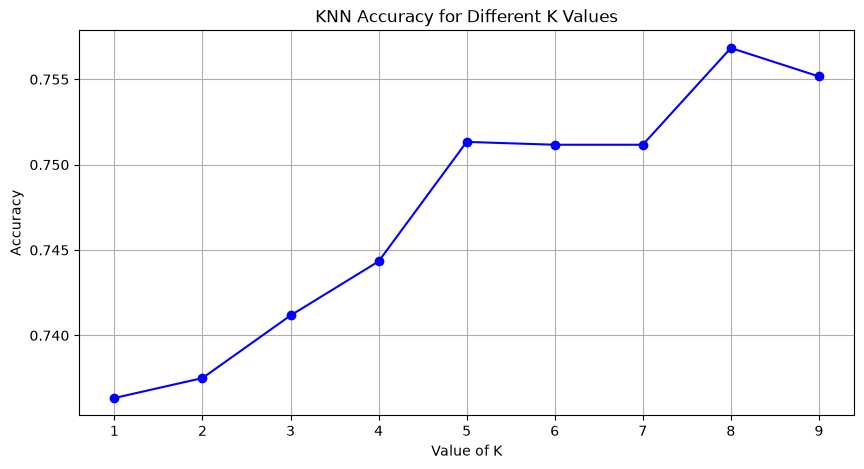

In [101]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt 

accuracy = []

# Loop to test K values from 1 to 49
for i in range(1, 10):
    knn = KNeighborsClassifier(n_neighbors=i, weights = 'uniform', n_jobs = -1, metric='euclidean')
    knn.fit(X_train_sc, y_train)
    y_pred = knn.predict(X_test_sc)
    accuracy.append(accuracy_score(y_test, y_pred))

# Plotting K values vs Accuracy
plt.figure(figsize=(10, 5))
plt.plot(range(1, 10), accuracy, marker='o', linestyle='-', color='b')
plt.title('KNN Accuracy for Different K Values')
plt.xlabel('Value of K')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from mlxtend.plotting import plot_decision_regions

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_sc)

knn = KNeighborsClassifier(n_neighbors = 7)
knn.fit(X_pca, y_train)

# 4. MLxtend se Decision Boundary plot ki
plt.figure(figsize=(8, 6))
plot_decision_regions(X_pca, y_train, clf=knn, legend=2)

# Graph ki styling
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('K-nn Decision Boundary (after PCA)')
plt.show()

In [104]:
# use the parameters 

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

knn = KNeighborsClassifier(n_neighbors = 7, weights = 'uniform', n_jobs = -1, metric='euclidean')
knn.fit(X_train_sc, y_train)
y_pred = knn.predict(X_test_sc)


print("accuracy", accuracy_score(y_test,y_pred))
print("confusion_matrix: \n", confusion_matrix(y_test, y_pred))

print("classification_report", classification_report(y_test, y_pred))


accuracy 0.7511666666666666
confusion_matrix: 
 [[3129  683]
 [ 810 1378]]
classification_report               precision    recall  f1-score   support

           0       0.79      0.82      0.81      3812
           1       0.67      0.63      0.65      2188

    accuracy                           0.75      6000
   macro avg       0.73      0.73      0.73      6000
weighted avg       0.75      0.75      0.75      6000



In [105]:
# Training accuracy
y_train_pred = knn.predict(X_train_sc)
train_acc = accuracy_score(y_train, y_train_pred)

# Testing accuracy
y_test_pred = knn.predict(X_test_sc)
test_acc = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)
print("Accuracy Gap:", train_acc - test_acc)

Training Accuracy: 0.8200833333333334
Testing Accuracy: 0.7511666666666666
Accuracy Gap: 0.06891666666666674


In [83]:
0.080 * 100

8.0

In [70]:
knn.get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'cosine',
 'metric_params': None,
 'n_jobs': -1,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'uniform'}

In [106]:
knn.n_features_in_

422

KeyboardInterrupt: 

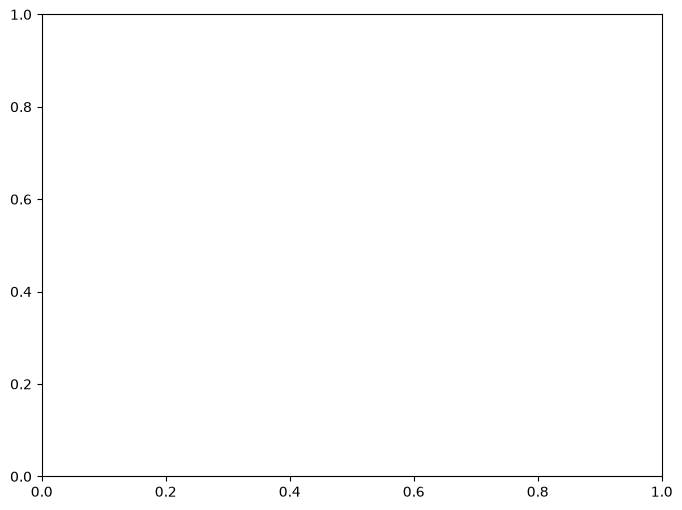

In [61]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from mlxtend.plotting import plot_decision_regions

# 2. PCA ka use karke 4 features ko 2 features (components) me reduce kiya
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_sc)

# 3. KNN model train kiya 2D data par (y_train use karein yahan)
knn = KNeighborsClassifier(n_neighbors = 5, weights = 'distance', metric='cosine', n_jobs = -1)
knn.fit(X_pca, y_train)

# 4. MLxtend se Decision Boundary plot ki (yahan bhi y_train use karein)
plt.figure(figsize=(8, 6))
plot_decision_regions(X_pca, y_train, clf=knn, legend=2)

# Graph ki styling
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('K-NN Decision Boundary (after PCA)')
plt.show()

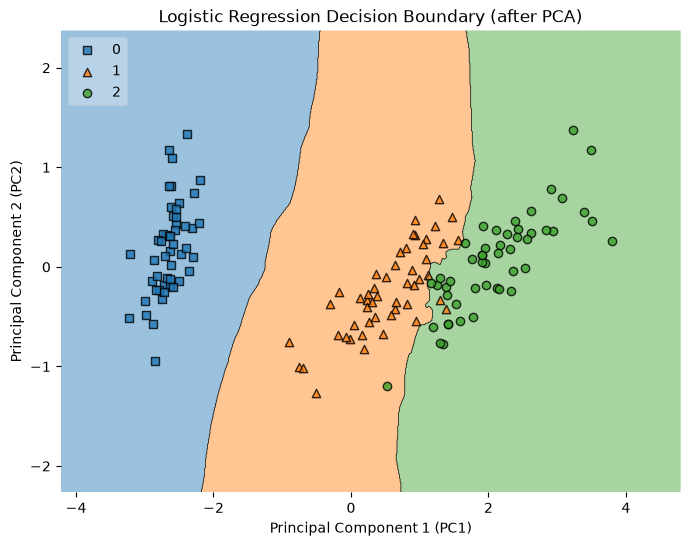

In [57]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from mlxtend.plotting import plot_decision_regions

# 1. Dataset load kiya (Iris dataset me 4 features hote hain)
iris = load_iris()
X = iris.data
y = iris.target

# 2. PCA ka use karke 4 features ko 2 features (components) me reduce kiya
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# 3. Logistic Regression model train kiya 2D data par
knn = KNeighborsClassifier()
knn.fit(X_pca, y)

# 4. MLxtend se Decision Boundary plot ki
plt.figure(figsize=(8, 6))
plot_decision_regions(X_pca, y, clf=knn, legend=2)

# Graph ki styling
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.title('Logistic Regression Decision Boundary (after PCA)')
plt.show()

